# Exposure reconciled to a reference engine within Monte Carlo error, and golden values for wrong-way risk

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 03, 06 and 07 of this topic
- **Reading time:** about 45 minutes

**Question:** Which results of the counterparty engine can honestly be called reconciled to a reference engine, with the failures printed beside the successes, and how close do its wrong-way calibration and its closed forms come to the published values they must reproduce?

## Objectives

By the end of this notebook you can:

- state the claim of the SDD for the counterparty engine, what it covers and what it does not claim;
- recompute the engine's exposure and compare it with the committed profile of ORE 1.8.17.0 within combined Monte Carlo standard errors, for the two variants where the claim holds;
- read the other variants as reported gaps, with the figure that says how large each gap is;
- check the closed forms against the QuantLib rows, and the wrong-way calibration against the printed digits of the paper's Appendix;
- say why a reconciliation that reports its failures is stronger evidence than one that reports only its successes.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import cva
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw
from riskvalidation.validation import ccr as vc

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The six variants of case C12 (counterparty credit risk) under `data/derived/C12/`, on synthetic swaps and the US Treasury par curve of 2025-09-30 (licence class `mirror-allowed`). Each carries the `ore_reconciliation` block (ORE 1.8.17.0, run natively on the same trades and curve with 10,000 antithetic samples; not run here) and the engine's tests. Notebooks 06 and 07 explain each test; this one reads them as evidence for a claim.

- **Files read:** the six documents `single-swap.json`, `netting-set.json`, `csa-mpor-10d.json`, `csa-mpor-20d.json`, `with-im.json` and `wrong-way-risk.json`.
- **What is recomputed live:** the engine's expected exposure of the single swap and of the netting set, from the committed curve, calibration, seed and number of paths (notebook 01), and the comparison with ORE's committed profile; the wrong-way calibration of the paper's Appendix.
- **What is read:** ORE's profiles and the QuantLib comparison rows.

The next cell loads the documents and checks that every committed file the claim cites exists and was baked by the engine version installed here.

In [2]:
# Load the six committed variants of C12 and check the files, the baking version and the licence class
ROOT = Path("../../..").resolve()
names = ["single-swap", "netting-set", "csa-mpor-10d", "csa-mpor-20d", "with-im", "wrong-way-risk"]
paths = {n: ROOT / "data" / "derived" / "C12" / f"{n}.json" for n in names}
docs = {n: json.loads(p.read_text(encoding="utf-8")) for n, p in paths.items()}
LIGHT = {"green": "green", "red": "red", "amber": "amber"}

present = all(p.is_file() for p in paths.values())
print("files present:", "yes" if present else "no", "| installed engine:", rv.__version__)
print("baked by riskvalidation, by variant:",
      {n: d["provenance"]["riskvalidation_version"] for n, d in docs.items()})
print("truth status:", {d["provenance"]["truth_status"] for d in docs.values()})
print("licence classes of the inputs:", docs["single-swap"]["provenance"]["licence_classes"])
print("ORE version:", docs["single-swap"]["outputs"]["ore_reconciliation"]["ore_version"])

files present: yes | installed engine: 1.0.1
baked by riskvalidation, by variant: {'single-swap': '1.0.1', 'netting-set': '1.0.1', 'csa-mpor-10d': '1.0.1', 'csa-mpor-20d': '1.0.1', 'with-im': '1.0.1', 'wrong-way-risk': '1.0.1'}
truth status: {'synthetic-calibrated'}
licence classes of the inputs: {'treasury-par-curve': 'mirror-allowed', 'treasury-hqm': 'mirror-allowed'}
ORE version: 1.8.17.0


## Method

### Step 1: the engine side, recomputed

For the claim to mean anything the engine side must not be a number copied from a file. We rebuild the single-swap and the netting-set expected exposure from the curve, the calibration, the seed and the number of paths (the construction of notebook 01, with the same time grid), in the forward measure that ORE's discounted profile is brought to. The next cell does it for both variants, so that what we compare with ORE is computed here and not copied from a file.

In [3]:
# Rebuild the simulation of notebook 01 and the EE of the single swap and of the netting set
base = docs["netting-set"]["outputs"]
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [
    sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer",
            t["start_years"], t["maturity_years"], t["fixed_frequency_per_year"])
    for t in base["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in (14 / 360, 28 / 360)]), 12))
grid = sw.simulation_grid(merged, swaps)
r = hw1f.simulate_short_rate(grid, a, sigma, forward, named["path_count"]["value"], named["seed"]["value"])
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
p0r, nm = p0(report), numeraire[:, ix]

live = {}
for key, members in (("single-swap", [0]), ("netting-set", [0, 1, 2, 3])):
    e_d, e_se = ex.expected_exposure(ex.net_values(values[members][:, :, ix]), nm)
    live[key] = (e_d / p0r, e_se / p0r)
    print(f"{key:12s} peak of the rebuilt EE:", round(float(live[key][0].max()), 0),
          "at", float(report[live[key][0].argmax()]), "y")

single-swap  peak of the rebuilt EE: 294524.0 at 5.0 y
netting-set  peak of the rebuilt EE: 294524.0 at 5.0 y


### Step 2: the reconciliation with ORE

Now the engine's rebuilt profile goes against ORE's committed one, point by point, through the engine's `reconcile_ee_profile`, with each side's own Monte Carlo error. This is the claim in its sharpest form: two independent implementations, one in Python and one in C++, of the same Hull-White model on the same curve and trades, with the difference measured in units of its own noise. For the EEPE and the CVA the combined error is the one recorded in the document. The next cell prints, for the two variants of the claim, the statistic, the number of dates inside the gate, and the EEPE and CVA differences.

In [4]:
# Reconcile the rebuilt EE of the two variants with ORE's profile, and read the EEPE and CVA differences
print(f"{'variant':13s}{'statistic':>12s}{'dates inside 2 se':>26s}{'light':>8s}"
      f"{'EEPE (se)':>12s}{'CVA (se)':>11s}")
for key in ("single-swap", "netting-set"):
    o = docs[key]["outputs"]["ore_reconciliation"]
    ref, ref_se = np.array(o["ore_ee"]["values"]), np.array(o["ore_ee"]["mc_se"])
    t = vc.reconcile_ee_profile(live[key][0], live[key][1], ref, ref_se, k_se=2.0)
    inside = int(np.sum(np.abs(live[key][0] - ref) <= 2.0 * np.sqrt(live[key][1] ** 2 + ref_se**2)))
    e, c = o["eepe_agreement"], o["cva_agreement"]
    print(f"{key:13s}{t.statistic:12.3f}{inside:22d} /{report.size:3d}{LIGHT[t.light.value]:>8s}", end="")
    print(f"{e['difference'] / e['combined_se']:12.2f}{c['difference'] / c['combined_se']:11.2f}")
print("gate (k_se):", t.extras["thresholds"]["k_se"])

variant         statistic         dates inside 2 se   light   EEPE (se)   CVA (se)
single-swap         0.775                    33 / 33   green        0.30       0.37
netting-set         0.715                    33 / 33   green        0.31       0.40
gate (k_se): 2.0


The next cell draws the rebuilt EE of the single swap and of the netting set over ORE's profile, with a band of two combined standard errors around ORE's.

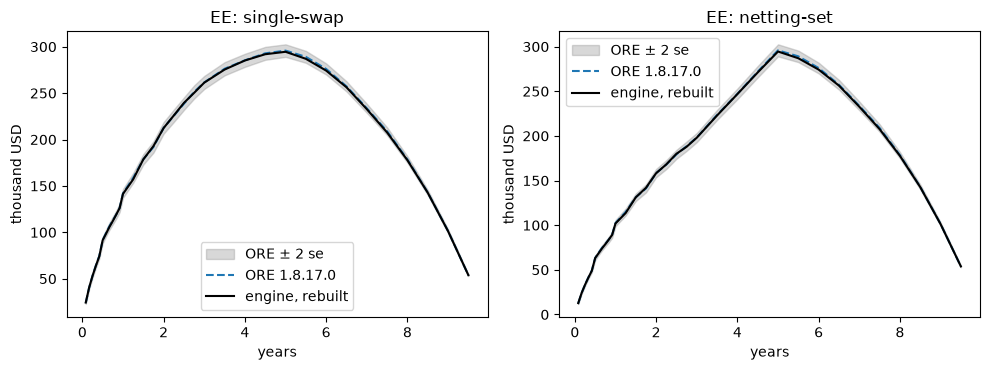

In [5]:
# Draw the rebuilt EE over ORE's profile for the single swap and the netting set, with a band of 2 combined se
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, key in zip(axes, ("single-swap", "netting-set")):
    o = docs[key]["outputs"]["ore_reconciliation"]
    ref, ref_se = np.array(o["ore_ee"]["values"]), np.array(o["ore_ee"]["mc_se"])
    band = 2 * np.sqrt(live[key][1] ** 2 + ref_se**2)
    ax.fill_between(report, (ref - band) / 1e3, (ref + band) / 1e3, color="grey", alpha=0.3, label="ORE ± 2 se")
    ax.plot(report, ref / 1e3, "--", color="tab:blue", label="ORE 1.8.17.0")
    ax.plot(report, live[key][0] / 1e3, color="black", lw=1.5, label="engine, rebuilt")
    ax.set_xlabel("years")
    ax.set_ylabel("thousand USD")
    ax.set_title(f"EE: {key}")
    ax.legend()
fig.tight_layout()
plt.show()

In both panels the black line runs inside the grey band, the combined error of the two engines, from the first date to the last, and follows the dashed ORE line through the peak. This is the claim at its sharpest: a Python simulation and a C++ simulation of the same Hull-White model, written independently, produce profiles that cannot be told apart given their own noise. The band is two combined standard errors wide, a gate fixed before looking at the data. The panels cover two books without collateral; the next section turns to the books where the claim does not hold.

## Comparison

What the practice offers, as the persisted research of the case records it from the primary sources. Toolkits for counterparty exposure give the estimators and the simulation and leave the reconciliation to the user: ORE is the most complete open engine and the natural reference, and QuantLib supplies the closed forms of the Hull-White model; neither ships a statement of how far an independent implementation agrees with it. The research's own rule for Contraste is that ORE's and QuantLib's numbers may be presented as a validation of the product only **to the extent of the reconciliations actually run**, never beyond them. The engineering practice behind a reconciliation is the one used in this topic: both sides carry a Monte Carlo error, the difference is stated in combined standard errors, and a gate is fixed before the comparison, here two combined standard errors, a Contraste internal gate and not a regulatory one.

## Evidence

This notebook demonstrates the claim of the SDD, for the counterparty engine: the reconciliations against reference engines that exist today, and the gap reported.

- **What is claimed.** The engine's single-swap and netting-set exposure agrees with ORE 1.8.17.0 at every one of the 33 report dates within two combined Monte Carlo standard errors, and so do the EEPE and the CVA. The engine's Hull-White bond options and swaptions agree with QuantLib 1.44 to a relative $10^{-6}$. The wrong-way calibration reproduces the printed values of the Hull and White (2012) Appendix: the hazards within half a unit of the last printed digit and the printed $a(t^*)$ within 1.32 units.
- **What is reported as a gap and not claimed.** The collateralised variants (CSA with 10 and with 20 days) and the initial-margin variant do not agree with ORE: the largest gaps of the EE profile are 9.9, 7.1 and 11.7 combined standard errors, the CVA differs by 15.9 and 9.9 standard errors in the two CSA variants, and ORE's mean dynamic initial margin is 0.88 of the engine's. The document records them as findings with a cause partly identified (the minimum transfer amount) and partly open.
- **What is not claimed at all.** The wrong-way variant against ORE (a different model: there is no reference), and the model against the market (notebook 06: it is rejected).
- **Why this goes beyond.** The research found toolkits that ship estimators and leave the reconciliation to the user, and a rule that reference-engine numbers must not be claimed beyond the reconciliations actually run. Contraste runs them, in the open, with the failures printed beside the successes, on committed files anyone can re-open.

The evidence is in the committed documents (listed in the claim in the SDD), and every number above is printed by the cells of this notebook.

### Step 3: the gaps, reported

The claim covers the variants where the reconciliation holds, and the document reports the others. The next cell reads all six variants and sorts them with the document's own rule: reconciled, gap reported, or not applicable. For each one it shows the number of EE dates inside the gate, the EEPE and CVA differences in combined standard errors, and for the initial-margin variant the ratio of the two mean DIM. Nothing is hidden by averaging: the largest gap of each profile is printed.

In [6]:
# Sort the six variants by the document's own rule and print the size of each reported gap
claimed, gaps, na, worst = [], [], [], {}
print(f"{'variant':15s}{'verdict':18s}{'EE dates in 2 se':>24s}{'largest EE gap (se)':>28s}"
      f"{'EEPE (se)':>11s}{'CVA (se)':>10s}")
for n in names:
    o = docs[n]["outputs"]
    rec = o["ore_reconciliation"]
    if rec["status"] == "not-applicable":
        na.append(n)
        print(f"{n:15s}{'not applicable':18s}")
        continue
    ag = rec["agreement"]
    inside = sum(p["within_two_se"] for p in ag)
    worst[n] = max(abs(p["difference"]) / p["combined_se"] for p in ag)
    verdict = "claimed" if rec["all_within_two_se"] else "gap reported"
    (claimed if rec["all_within_two_se"] else gaps).append(n)
    e, c = rec["eepe_agreement"], rec["cva_agreement"]
    print(f"{n:15s}{verdict:18s}{inside:20d} /{len(ag):3d}{worst[n]:28.1f}", end="")
    print(f"{e['difference'] / e['combined_se']:11.2f}{c['difference'] / c['combined_se']:10.2f}")
print("claimed:", claimed, "| gap reported:", gaps, "| not applicable:", na)

variant        verdict                   EE dates in 2 se         largest EE gap (se)  EEPE (se)  CVA (se)
single-swap    claimed                             33 / 33                         0.8       0.30      0.37
netting-set    claimed                             33 / 33                         0.7       0.31      0.40
csa-mpor-10d   gap reported                        17 / 33                         9.9      -1.55    -15.89
csa-mpor-20d   gap reported                        21 / 33                         7.1      -2.20     -9.88
with-im        gap reported                        32 / 33                        11.7      -0.71     -1.40
wrong-way-risk not applicable    
claimed: ['single-swap', 'netting-set'] | gap reported: ['csa-mpor-10d', 'csa-mpor-20d', 'with-im'] | not applicable: ['wrong-way-risk']


The initial-margin variant has one more number to read: the mean dynamic initial margin of both engines, and the findings that the case itself recorded against ORE for the variants with a gap. The next cell prints both.

In [7]:
# The ratio of the two mean DIM, the engine's statistic on the DIM profile, and the findings recorded against ORE
im = docs["with-im"]["outputs"]
dim_py, dim_py_se = np.array(im["initial_margin"]["dim"]["values"]), np.array(im["initial_margin"]["dim"]["mc_se"])
dim_ore = np.array(im["ore_reconciliation"]["ore_dim"]["values"])
dim_ore_se = np.array(im["ore_reconciliation"]["ore_dim"]["mc_se"])
t_dim = vc.reconcile_ee_profile(dim_py, dim_py_se, dim_ore, dim_ore_se, k_se=2.0)
dim_points = im["ore_reconciliation"]["dim_agreement"]
print("initial margin: points of the mean DIM inside the gate:",
      sum(p["within_two_se"] for p in dim_points), "of", len(dim_points))
print("ORE / engine mean DIM ratio:", round(float(np.mean(dim_ore / dim_py)), 3),
      "| largest gap in combined se:", round(t_dim.statistic, 1))
print("findings recorded by the case against ORE (variant: titles):")
for n in gaps:
    titles = [f["title"]["en"][:70] for f in docs[n]["findings"] if "ORE" in f["title"]["en"]]
    print(" ", n, titles)

initial margin: points of the mean DIM inside the gate: 0 of 33
ORE / engine mean DIM ratio: 0.884 | largest gap in combined se: 137.4
findings recorded by the case against ORE (variant: titles):
  csa-mpor-10d ['1 red row on the CVA against ORE 1.8.17.0', '1 red row on the EE profile against ORE 1.8.17.0', '1 red row on the EE profile against ORE 1.8.17.0 (minimum transfer amo']
  csa-mpor-20d ['1 red row on the CVA against ORE 1.8.17.0', '1 red row on the EEPE against ORE 1.8.17.0', '1 red row on the EE profile against ORE 1.8.17.0', '1 red row on the EE profile against ORE 1.8.17.0 (minimum transfer amo']
  with-im ["1 red row on the mean initial margin against ORE's dynamic initial mar", '1 red row on the EE profile against ORE 1.8.17.0']


The next cell draws the largest standardised gap of the EE profile of each variant against the gate of two standard errors, and the gap along the dates for the single swap and the 10-day CSA.

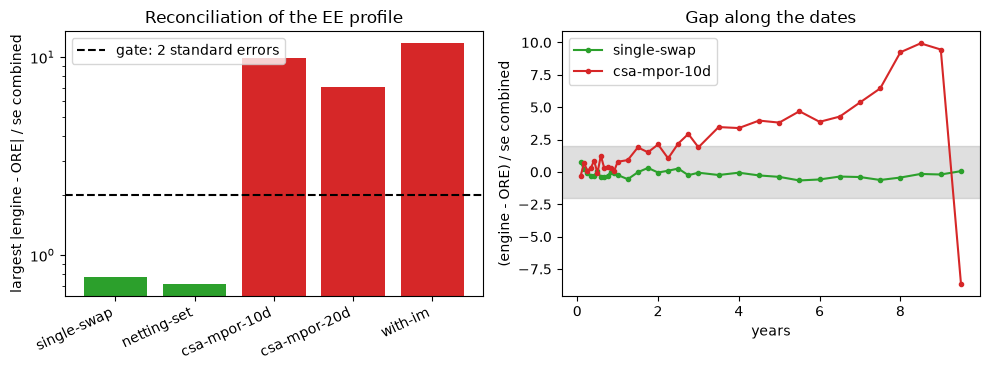

In [8]:
# Draw the largest standardised EE gap per variant against the gate (left) and the gap along the dates (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
checked = [n for n in names if n not in na]
colors = ["tab:green" if n in claimed else "tab:red" for n in checked]
left.bar(range(len(checked)), [worst[n] for n in checked], color=colors)
left.axhline(2.0, color="black", ls="--", label="gate: 2 standard errors")
left.set_yscale("log")
left.set_xticks(range(len(checked)), checked, rotation=25, ha="right")
left.set_ylabel("largest |engine - ORE| / se combined")
left.set_title("Reconciliation of the EE profile")
left.legend()
for n, color in (("single-swap", "tab:green"), ("csa-mpor-10d", "tab:red")):
    ag = docs[n]["outputs"]["ore_reconciliation"]["agreement"]
    gap = [-p["difference"] / p["combined_se"] for p in ag]
    right.plot([p["t"] for p in ag], gap, "o-", ms=3, color=color, label=n)
right.axhspan(-2, 2, color="grey", alpha=0.25)
right.set_xlabel("years")
right.set_ylabel("(engine - ORE) / se combined")
right.set_title("Gap along the dates")
right.legend()
fig.tight_layout()
plt.show()

On the left, the two claimed variants sit under the dashed gate and the three variants with collateral stand above it by a factor of four to six, on a log scale that makes the gap look smaller than it is. On the right, the single swap wanders inside the grey band while the 10-day CSA runs outside it over a long stretch of dates, on one side. Nothing is averaged away: the largest gap of each profile is plotted. The case records these gaps as findings, with the minimum transfer amount as the part of the cause that has been identified, and the figure is the evidence a reader needs to challenge that.

### Step 4: the other references

Two more references stand behind the claim. First, the closed forms of the Hull-White model against QuantLib 1.44, as four rows with both values and a gate of $10^{-6}$ in relative terms. Second, the wrong-way variant has no ORE reference, because ORE's example is a different model; its reference is the Appendix of Hull and White (2012), which prints a three-path calibration. The paper's digits are the golden values: the printed $a(t^*)$ and hazards $h_{ij}$. The engine's `wwr_calibrate_a` must give them, and at $b=0$ the engine's `wwr_cva` must return the independent CVA exactly. The next two cells check the four things.

In [9]:
# The four QuantLib rows, and the Appendix golden values against the engine's wrong-way calibration
ql = [row for row in docs["single-swap"]["tests"] if row["test_id"].startswith("ccr.quantlib")]
rel = [abs(row["extras"]["engine"] - row["extras"]["quantlib"]) / abs(row["extras"]["quantlib"]) for row in ql]
print("QuantLib rows:", len(ql), "| largest relative difference:", f"{max(rel):.2e}",
      "| gate 1e-6 holds:", "yes" if max(rel) < 1e-6 else "no")

w_app = np.array([[100.0, 100.0], [200.0, 300.0], [300.0, 400.0]])
target = cva.survival_from_spread(np.array([0.01, 0.01]), np.array([0.5, 1.0]), 1.0)
a_app, h_app = cva.wwr_calibrate_a(w_app, target, np.array([0.5, 0.5]), 0.01)
printed_a = np.array([-6.9128, -7.8509])
printed_h = np.array([[0.00270, 0.00735, 0.01998], [0.00106, 0.00782, 0.02126]])
unit_a, unit_h = 1e-4, 1e-5
print("a(t*) gap to the printed digits, in units of the last printed digit:",
      np.round(np.abs(a_app - printed_a) / unit_a, 2))
print("h largest gap, in units of the last printed digit:",
      round(float(np.max(np.abs(h_app.T - printed_h)) / unit_h), 2))
mean_survival = np.exp(-np.cumsum(h_app * 0.5, axis=1)).mean(axis=0)
print("largest gap between the average survival after each step and the target:",
      float(np.max(np.abs(mean_survival - target))))

QuantLib rows: 4 | largest relative difference: 9.50e-08 | gate 1e-6 holds: yes
a(t*) gap to the printed digits, in units of the last printed digit: [0.33 1.32]
h largest gap, in units of the last printed digit: 0.45
largest gap between the average survival after each step and the target: 1.1102230246251565e-16


The second cell recomputes the wrong-way variant: at $b=0$ the wrong-way CVA must be the independent CVA exactly, and at $b=1$ and $b=2$ it must rise by the amounts the sweep gives.

In [10]:
# The wrong-way CVA at b = 0 against the independent CVA, and its rise at b = 1 and b = 2
wwr = docs["wrong-way-risk"]["outputs"]
credit = wwr["cva_dva"]
survival = np.array([b["survival"] for b in credit["buckets"]])
dt = np.diff(np.concatenate([[0.0], report]))
v_net = ex.net_values(values[:, :, ix])
w, x_disc = v_net / 1e6, np.maximum(v_net, 0.0) / nm
epe_d = np.array(wwr["exposure"]["ee_discounted"]["values"])
pd_cp = cva.default_probabilities(np.concatenate([[1.0], survival]))
independent, _ = cva.cva(epe_d, pd_cp, credit["lgd"])
value0, _ = cva.wwr_cva(w, x_disc, survival, dt, credit["lgd"], 0.0)
print("wrong-way CVA at b = 0 equals the independent CVA exactly:",
      "yes" if value0 == independent else "no", "|", round(independent, 2))
for b in (1.0, 2.0):
    value, _ = cva.wwr_cva(w, x_disc, survival, dt, credit["lgd"], b)
    print(f"b = {b:.0f} | CVA {value:10.2f} | change vs independent {value / independent - 1:+.1%}")

wrong-way CVA at b = 0 equals the independent CVA exactly: yes | 9477.77
b = 1 | CVA   12439.56 | change vs independent +31.2%
b = 2 | CVA   15594.61 | change vs independent +64.5%


## Results

**Answer:** Two of the six variants reconcile with ORE 1.8.17.0 within Monte Carlo error: the single swap, with a largest gap of 0.775 combined standard errors, and the netting set of four swaps, with 0.715, both with all 33 dates inside the gate of 2. Three do not and say so: the CSA of 10 days (9.9 standard errors), the CSA of 20 days (7.1) and the variant with initial margin (11.7), where ORE's mean dynamic initial margin is 0.884 of the engine's; one has no reference. The engine's swaptions agree with QuantLib to a relative 9.5e-8, and its wrong-way calibration reproduces the paper's printed values to 1.32 units of the last printed digit at most.

- **The engine side is computed here.** The single-swap and netting-set expected exposure is rebuilt from the curve, the calibration, the seed and the number of paths, so what is compared with ORE is not a number copied from a file. The EEPE differs by 0.30 and 0.31 standard errors and the CVA by 0.37 and 0.40. The engine ran 20,000 paths; ORE ran 10,000 antithetic samples natively in about half a minute.
- **Where it does not, and by how much.** The CSA of 10 days has 17 of 33 dates inside the gate, an EEPE within the gate (-1.55) and a CVA 15.9 standard errors apart (ORE is lower). The CSA of 20 days has 21 of 33 dates inside, and both the EEPE (-2.20) and the CVA (-9.88) outside the gate. With initial margin 32 of 33 EE dates are inside the gate (largest gap 11.7, at one date), the EEPE and the CVA agree (-0.71 and -1.40), and none of the 33 points of the mean dynamic initial margin does. The case records each as a finding.
- **Closed forms and golden values.** The four QuantLib rows agree to a relative 9.5e-8 at most, inside the gate of 1e-6. The wrong-way calibration reproduces the hazards of the paper's Appendix to 0.45 of a unit of the last printed digit, the printed $a(t_1^*)$ to 0.33 and the printed $a(t_2^*)$ to 1.32 units (the paper prints -7.8509 and the root of its own equation, which the engine finds, rounds to -7.8508); the average survival equals the target to 1e-12. At $b=0$ the wrong-way CVA is the independent CVA exactly, and at $b=1$ and $b=2$ it is 31.2% and 64.5% above it.
- **What the claim is.** Two of the six variants reconcile with the reference engine within Monte Carlo error; three do not and say so; one has no reference. A reader who wants to challenge the claim has the profiles of both engines in the committed documents and the gate in the engine's test.

What this notebook does not show: why the collateralised variants differ (the minimum transfer amount explains most of the CSA gap in the document, and the remaining cause and the DIM difference are open), a reconciliation of the other engines of the product (portfolio, IRRBB, liquidity) with a reference, or a statement that the Hull-White model describes the market (notebook 06: it is rejected by the back-test).

## Summary

- The claim for the counterparty engine: the exposure of the single swap and of the netting set agrees with ORE 1.8.17.0 at every date within two combined standard errors, and with QuantLib 1.44 in the closed forms.
- The same reconciliation reports its failures: the CSA variants and the dynamic initial margin differ from ORE, with the size of each gap printed and the findings recorded.
- The wrong-way calibration has no ORE reference, so its golden values are the printed digits of the paper's Appendix, matched to about one unit of the last digit, and the identity at $b=0$.
- A reconciliation is evidence about two implementations of one model; it says nothing about whether the model fits the market.

**What to try next.** Tighten the gate to 1 standard error and count which variants stay claimed; list the findings of each document and compare their titles with the gaps printed here. This is the last notebook of the topic.

## References

- Open Source Risk Engine (ORE), release 1.8.17.0. https://github.com/OpenSourceRisk/Engine
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- QuantLib, the open-source quantitative finance library. https://github.com/lballabio/QuantLib
- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6